# Thực nghiệm Random Agent và Rule-Based Agent trên Caro 11×11

Notebook thực hiện: khởi tạo môi trường, kiểm thử luật chơi, xây dựng/khởi tạo hai agent từ `src/`, chạy tournament có cân bằng lượt đi trước, thống kê kết quả, vẽ biểu đồ và xuất video MP4.

**Quy ước:** bàn cờ 11×11; `X = 1` đi trước, `O = -1`; thắng khi có ít nhất 5 quân liên tiếp theo hàng, cột hoặc hai đường chéo. Các nước đi được mã hóa thành số nguyên `row * 11 + col`.

## 1. Import và cấu hình

In [16]:

import sys
from pathlib import Path
import importlib

# Thư mục gốc dự án
PROJECT_ROOT = Path(
    r"F:\TTNTNC\Caro\caro_ai_11x11"
).resolve()

# Thư mục chứa caro_env.py và heuristic.py
SRC_DIR = PROJECT_ROOT / "src"

# Kiểm tra cấu trúc
assert (SRC_DIR / "caro_env.py").exists(), "Không tìm thấy caro_env.py"
assert (SRC_DIR / "heuristic.py").exists(), "Không tìm thấy heuristic.py"

# Đưa src lên đầu đường dẫn tìm kiếm module
src_path = str(SRC_DIR)

if src_path in sys.path:
    sys.path.remove(src_path)

sys.path.insert(0, src_path)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC_DIR:", SRC_DIR)
print("Đã cấu hình PYTHONPATH thành công!")


PROJECT_ROOT: F:\TTNTNC\Caro\caro_ai_11x11
SRC_DIR: F:\TTNTNC\Caro\caro_ai_11x11\src
Đã cấu hình PYTHONPATH thành công!


In [17]:
from pathlib import Path
import sys, os, time, random, shutil, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.caro_env import CaroEnv
from src.agents import RandomAgent, RuleBasedAgent

BOARD_SIZE = 11
WIN_LENGTH = 5
GAMES_PER_MATCHUP = 100
SEED = 42

RESULTS_DIR = PROJECT_ROOT / "results"
TABLE_DIR = RESULTS_DIR / "tables"
CHART_DIR = RESULTS_DIR / "charts"
VIDEO_DIR = RESULTS_DIR / "videos"
for folder in (TABLE_DIR, CHART_DIR, VIDEO_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def play_game(agent_x, agent_o, board_size=11, win_length=5, record=False):
    """Chạy một ván trực tiếp trong notebook; không phụ thuộc src/tournament.py."""
    env = CaroEnv(board_size, win_length)
    history = [env.board.copy()] if record else []
    x_times, o_times = [], []
    x_search, o_search = [], []

    while not env.is_terminal():
        agent = agent_x if env.current_player == 1 else agent_o
        action = agent.select_action(env)
        _, _, done, _ = env.step(action)

        elapsed = float(getattr(agent, "last_move_time_ms", 0.0))
        searched = int(getattr(agent, "last_search_count", 1))
        if agent is agent_x:
            x_times.append(elapsed)
            x_search.append(searched)
        else:
            o_times.append(elapsed)
            o_search.append(searched)

        if record:
            history.append(env.board.copy())

    return {
        "winner": env.winner if env.winner != 0 else None,
        "moves": len(env.history),
        "x_avg_ms": float(np.mean(x_times)) if x_times else 0.0,
        "o_avg_ms": float(np.mean(o_times)) if o_times else 0.0,
        "x_avg_search_count": float(np.mean(x_search)) if x_search else 0.0,
        "o_avg_search_count": float(np.mean(o_search)) if o_search else 0.0,
        "history": history,
    }


def run_matchup(factory_a, factory_b, games=100, board_size=11,
                win_length=5, seed=42):
    """
    A và B đổi bên X/O luân phiên: 50 ván A đi trước, 50 ván B đi trước
    nếu games=100. Không import hoặc gọi src/tournament.py.
    """
    rows = []
    for game_index in range(games):
        a_agent = factory_a(seed + 2 * game_index)
        b_agent = factory_b(seed + 2 * game_index + 1)

        a_is_x = (game_index % 2 == 0)
        agent_x, agent_o = (a_agent, b_agent) if a_is_x else (b_agent, a_agent)

        result = play_game(agent_x, agent_o, board_size, win_length, record=False)
        winner = result["winner"]
        if winner is None:
            outcome = "Draw"
        elif (winner == 1 and a_is_x) or (winner == -1 and not a_is_x):
            outcome = "A"
        else:
            outcome = "B"

        rows.append({
            "game": game_index + 1,
            "winner": outcome,
            "moves": result["moves"],
            "a_side": "X" if a_is_x else "O",
            "x_avg_ms": result["x_avg_ms"],
            "o_avg_ms": result["o_avg_ms"],
            "a_avg_ms": result["x_avg_ms"] if a_is_x else result["o_avg_ms"],
            "b_avg_ms": result["o_avg_ms"] if a_is_x else result["x_avg_ms"],
            "x_avg_search_count": result["x_avg_search_count"],
            "o_avg_search_count": result["o_avg_search_count"],
            "a_avg_search_count": result["x_avg_search_count"] if a_is_x else result["o_avg_search_count"],
            "b_avg_search_count": result["o_avg_search_count"] if a_is_x else result["x_avg_search_count"],
        })
        if (game_index + 1) % 10 == 0:
            print(f"Hoàn thành {game_index + 1}/{games} ván")
    return rows


print("Project:", PROJECT_ROOT)
print("Số ván thực nghiệm:", GAMES_PER_MATCHUP)


Project: f:\TTNTNC\Caro\caro_ai_11x11
Số ván thực nghiệm: 100


## 2. Kiểm tra môi trường Caro

In [18]:
env = CaroEnv(BOARD_SIZE, WIN_LENGTH)

print("Kích thước bàn:", env.board.shape)
print("Số nước đi hợp lệ ban đầu:", len(env.legal_actions()))

env.render()

Kích thước bàn: (11, 11)
Số nước đi hợp lệ ban đầu: 121
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  .  .  .  .  .  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .


'    0  1  2  3  4  5  6  7  8  9 10\n 0  .  .  .  .  .  .  .  .  .  .  .\n 1  .  .  .  .  .  .  .  .  .  .  .\n 2  .  .  .  .  .  .  .  .  .  .  .\n 3  .  .  .  .  .  .  .  .  .  .  .\n 4  .  .  .  .  .  .  .  .  .  .  .\n 5  .  .  .  .  .  .  .  .  .  .  .\n 6  .  .  .  .  .  .  .  .  .  .  .\n 7  .  .  .  .  .  .  .  .  .  .  .\n 8  .  .  .  .  .  .  .  .  .  .  .\n 9  .  .  .  .  .  .  .  .  .  .  .\n10  .  .  .  .  .  .  .  .  .  .  .'

## 3. Kiểm tra hai agent trả về hành động hợp lệ

In [19]:
env = CaroEnv(BOARD_SIZE, WIN_LENGTH)

agents_smoke_test = [
    RandomAgent(seed=SEED),
    RuleBasedAgent()
]

for agent in agents_smoke_test:
    action = agent.select_action(env)
    legal_actions = env.legal_actions()

    print(
        f"{agent.name}: "
        f"action={action}, "
        f"row={action // BOARD_SIZE}, "
        f"col={action % BOARD_SIZE}, "
        f"legal={action in legal_actions}"
    )

    assert action in legal_actions, (
        f"{agent.name} chọn nước đi không hợp lệ: {action}"
    )

Random: action=81, row=7, col=4, legal=True
Rule-Based Heuristic Greedy Look-Ahead: action=60, row=5, col=5, legal=True


## 4. Minh họa một ván đấu

In [20]:
# Kiểm chứng ba tình huống chiến thuật bắt buộc trong yêu cầu.

def make_test_env(x_stones=(), o_stones=(), current_player=1):
    test_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
    for r, c in x_stones:
        test_env.board[r, c] = 1
        test_env.history.append(r * BOARD_SIZE + c)
    for r, c in o_stones:
        test_env.board[r, c] = -1
        test_env.history.append(r * BOARD_SIZE + c)
    test_env.current_player = current_player
    return test_env

test_agent = RuleBasedAgent()


# (a) AI có thể nối quân thứ 5 ở một trong hai đầu để thắng ngay.
env_win = make_test_env(
    x_stones=[(5, 1), (5, 2), (5, 3), (5, 4)]
)

action_win = test_agent.select_action(env_win)

winning_actions = {
    5 * BOARD_SIZE + 0,  # (5, 0)
    5 * BOARD_SIZE + 5,  # (5, 5)
}

assert action_win in winning_actions, (
    f"AI không chọn nước thắng ngay. "
    f"Chọn: {divmod(action_win, BOARD_SIZE)}, "
    f"Kỳ vọng một trong: {[(5, 0), (5, 5)]}"
)

print("PASS (a) Thắng ngay:", divmod(action_win, BOARD_SIZE))
# (b) Đối thủ có 4 quân; AI phải chặn một trong hai đầu thắng.
env_block = make_test_env(o_stones=[(5, 1), (5, 2), (5, 3), (5, 4)])
action_block = test_agent.select_action(env_block)
assert action_block in {5 * BOARD_SIZE + 0, 5 * BOARD_SIZE + 5}
print("PASS (b) Chặn đối thủ:", divmod(action_block, BOARD_SIZE))

# (c) Cả hai bên đều có thể tạo open-four; luật ưu tiên tấn công của AI.
env_conflict = make_test_env(
    x_stones=[(4, 3), (4, 4), (4, 5)],
    o_stones=[(6, 3), (6, 4), (6, 5)],
)
action_conflict = test_agent.select_action(env_conflict)
assert action_conflict in {4 * BOARD_SIZE + 2, 4 * BOARD_SIZE + 6}
print("PASS (c) Xung đột: ưu tiên tạo open-four:", divmod(action_conflict, BOARD_SIZE))

# Minh họa một ván ngắn hoàn chỉnh để xác nhận giao diện play_game.
demo = play_game(RandomAgent(SEED), RuleBasedAgent(), BOARD_SIZE, WIN_LENGTH, record=False)
print({k: v for k, v in demo.items() if k != "history"})


PASS (a) Thắng ngay: (5, 0)
PASS (b) Chặn đối thủ: (5, 5)
PASS (c) Xung đột: ưu tiên tạo open-four: (4, 6)
{'winner': -1, 'moves': 10, 'x_avg_ms': 0.0, 'o_avg_ms': 10.599899990484118, 'x_avg_search_count': 1.0, 'o_avg_search_count': 726.2}


## 5. Tournament 100 ván: Random vs Rule-Based Heuristic-Look-Ahead


In [21]:

matchups = {
    # 1. Random vs Random
    "Random vs Random": (
        lambda seed: RandomAgent(seed=seed, name="Random A"),
        lambda seed: RandomAgent(seed=seed + 1, name="Random B"),
    ),

    # 2. Rule-Based vs Rule-Based
    "Rule-Based vs Rule-Based": (
        lambda seed: RuleBasedAgent(name="Rule-Based A"),
        lambda seed: RuleBasedAgent(name="Rule-Based B"),
    ),

    # 3. Random vs Rule-Based
    "Random vs Rule-Based Heuristic-LookAhead": (
        lambda seed: RandomAgent(seed=seed, name="Random"),
        lambda seed: RuleBasedAgent(
            name="Rule-Based Heuristic-LookAhead"
        ),
    ),

    # 4. Rule-Based vs Random
    "Rule-Based Heuristic-LookAhead vs Random": (
        lambda seed: RuleBasedAgent(
            name="Rule-Based Heuristic-LookAhead"
        ),
        lambda seed: RandomAgent(seed=seed + 1, name="Random"),
    ),
}


# ==========================================
# RUN ALL MATCHUPS
# ==========================================

all_results = []

for matchup_name, (factory_a, factory_b) in matchups.items():

    print("\n" + "=" * 65)
    print(f"Đang chạy: {matchup_name}")
    print("=" * 65)

    rows = run_matchup(
        factory_a,
        factory_b,
        games=GAMES_PER_MATCHUP,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED,
    )

    for row in rows:
        row["matchup"] = matchup_name

    all_results.extend(rows)

    print(f"Hoàn thành: {len(rows)} ván")


# ==========================================
# SAVE RESULTS
# ==========================================

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    TABLE_DIR / "game_logs.csv",
    index=False,
    encoding="utf-8-sig"
)

display(results_df.head(10))

print("\n" + "=" * 65)
print("TỔNG KẾT THỰC NGHIỆM")
print("=" * 65)

print("Tổng số cặp đối đầu:", len(matchups))
print("Số ván mỗi cặp:", GAMES_PER_MATCHUP)
print("Tổng số ván:", len(results_df))

if "a_side" in results_df.columns:
    print(
        "Số ván A đi trước (X):",
        int((results_df["a_side"] == "X").sum())
    )

    print(
        "Số ván A đi sau (O):",
        int((results_df["a_side"] == "O").sum())
    )

print("\nSố ván theo từng cặp:")
display(
    results_df.groupby("matchup").size().reset_index(name="games")
)



Đang chạy: Random vs Random
Hoàn thành 10/100 ván
Hoàn thành 20/100 ván
Hoàn thành 30/100 ván
Hoàn thành 40/100 ván
Hoàn thành 50/100 ván
Hoàn thành 60/100 ván
Hoàn thành 70/100 ván
Hoàn thành 80/100 ván
Hoàn thành 90/100 ván
Hoàn thành 100/100 ván
Hoàn thành: 100 ván

Đang chạy: Rule-Based vs Rule-Based
Hoàn thành 10/100 ván
Hoàn thành 20/100 ván
Hoàn thành 30/100 ván
Hoàn thành 40/100 ván
Hoàn thành 50/100 ván
Hoàn thành 60/100 ván
Hoàn thành 70/100 ván
Hoàn thành 80/100 ván
Hoàn thành 90/100 ván
Hoàn thành 100/100 ván
Hoàn thành: 100 ván

Đang chạy: Random vs Rule-Based Heuristic-LookAhead
Hoàn thành 10/100 ván
Hoàn thành 20/100 ván
Hoàn thành 30/100 ván
Hoàn thành 40/100 ván
Hoàn thành 50/100 ván
Hoàn thành 60/100 ván
Hoàn thành 70/100 ván
Hoàn thành 80/100 ván
Hoàn thành 90/100 ván
Hoàn thành 100/100 ván
Hoàn thành: 100 ván

Đang chạy: Rule-Based Heuristic-LookAhead vs Random
Hoàn thành 10/100 ván
Hoàn thành 20/100 ván
Hoàn thành 30/100 ván
Hoàn thành 40/100 ván
Hoàn thành 50/100

,game,winner,moves,a_side,x_avg_ms,o_avg_ms,a_avg_ms,b_avg_ms,x_avg_search_count,o_avg_search_count,a_avg_search_count,b_avg_search_count,matchup
0,1,A,73,X,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
1,2,A,62,O,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
2,3,A,69,X,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
3,4,B,59,O,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
4,5,B,74,X,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
5,6,B,79,O,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
6,7,A,63,X,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
7,8,B,69,O,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
8,9,B,50,X,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random
9,10,A,78,O,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,Random vs Random



TỔNG KẾT THỰC NGHIỆM
Tổng số cặp đối đầu: 4
Số ván mỗi cặp: 100
Tổng số ván: 400
Số ván A đi trước (X): 200
Số ván A đi sau (O): 200

Số ván theo từng cặp:


,matchup,games
0,Random vs Random,100
1,Random vs Rule-Based Heuristic-LookAhead,100
2,Rule-Based Heuristic-LookAhead vs Random,100
3,Rule-Based vs Rule-Based,100


## 6. Bảng tổng hợp Thắng / Hòa / Thua và Score

In [22]:
summary_rows = []
for matchup_name, group in results_df.groupby("matchup", sort=False):
    a_wins = int((group["winner"] == "A").sum())
    b_wins = int((group["winner"] == "B").sum())
    draws = int((group["winner"] == "Draw").sum())
    n = len(group)
    a_score = a_wins + 0.5 * draws
    b_score = b_wins + 0.5 * draws
    summary_rows.append({
        "Matchup": matchup_name,
        "Games": n,
        "A wins": a_wins,
        "B wins": b_wins,
        "Draws": draws,
        "A win rate (%)": round(100 * a_wins / n, 2),
        "B win rate (%)": round(100 * b_wins / n, 2),
        "Draw rate (%)": round(100 * draws / n, 2),
        "A Score (W + 0.5D)": round(a_score, 2),
        "B Score (W + 0.5D)": round(b_score, 2),
        "A Score rate (%)": round(100 * a_score / n, 2),
        "B Score rate (%)": round(100 * b_score / n, 2),
        "Avg moves": round(group["moves"].mean(), 2),
        "Avg A decision (ms)": round(group["a_avg_ms"].mean(), 3),
        "Avg B decision (ms)": round(group["b_avg_ms"].mean(), 3),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLE_DIR / "tournament_summary.csv", index=False, encoding="utf-8-sig")
display(summary_df)


,Matchup,Games,A wins,B wins,Draws,A win rate (%),B win rate (%),Draw rate (%),A Score (W + 0.5D),B Score (W + 0.5D),A Score rate (%),B Score rate (%),Avg moves,Avg A decision (ms),Avg B decision (ms)
0,Random vs Random,100,54,46,0,54.0,46.0,0.0,54.0,46.0,54.0,46.0,70.36,0.000,0.000
1,Rule-Based vs Rule-Based,100,0,0,100,0.0,0.0,100.0,50.0,50.0,50.0,50.0,121.00,15.406,15.412
2,Random vs Rule-Based Heuristic-LookAhead,100,0,100,0,0.0,100.0,0.0,0.0,100.0,0.0,100.0,9.80,0.000,10.449
3,Rule-Based Heuristic-LookAhead vs Random,100,100,0,0,100.0,0.0,0.0,100.0,0.0,100.0,0.0,9.80,10.320,0.000


## 7. Phân tích hiệu năng theo từng vai trò

In [23]:
performance_df = (results_df.groupby("matchup")
                  .agg(games=("game", "count"),
                       avg_moves=("moves", "mean"),
                       avg_A_ms=("a_avg_ms", "mean"),
                       avg_B_ms=("b_avg_ms", "mean"),
                       avg_A_search_count=("a_avg_search_count", "mean"),
                       avg_B_search_count=("b_avg_search_count", "mean"))
                  .reset_index())
numeric_cols = ["avg_moves", "avg_A_ms", "avg_B_ms",
                "avg_A_search_count", "avg_B_search_count"]
performance_df[numeric_cols] = performance_df[numeric_cols].round(3)
performance_df.to_csv(TABLE_DIR / "agent_performance.csv", index=False, encoding="utf-8-sig")
display(performance_df)


,matchup,games,avg_moves,avg_A_ms,avg_B_ms,avg_A_search_count,avg_B_search_count
0,Random vs Random,100,70.36,0.000,0.000,1.000,1.000
1,Random vs Rule-Based Heuristic-LookAhead,100,9.80,0.000,10.449,1.000,659.943
2,Rule-Based Heuristic-LookAhead vs Random,100,9.80,10.320,0.000,659.771,1.000
3,Rule-Based vs Rule-Based,100,121.00,15.406,15.412,715.202,715.202


## 8. Biểu đồ tỷ lệ thắng và số nước trung bình

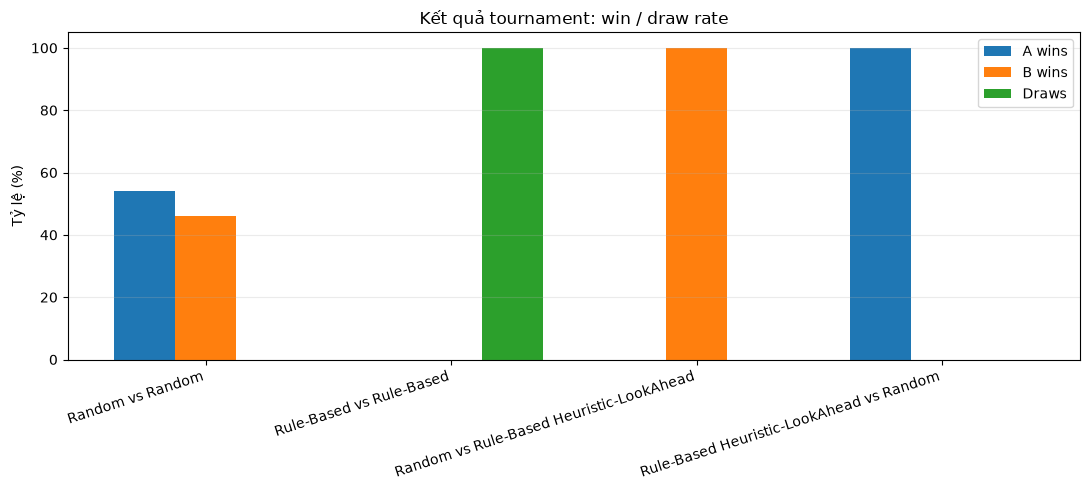

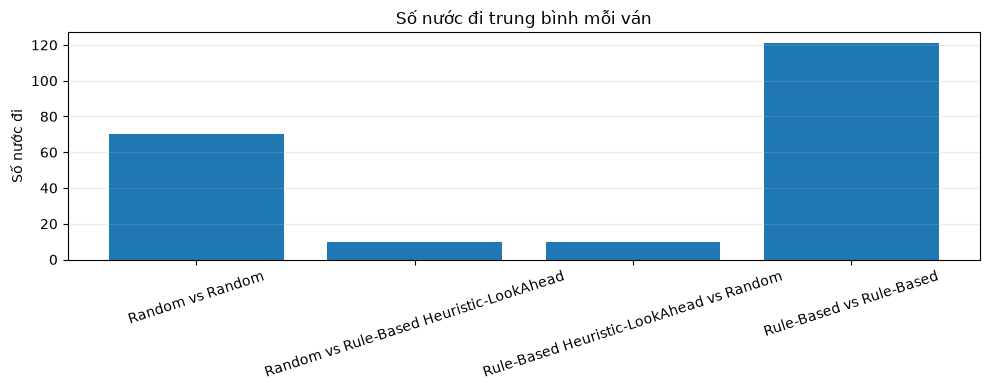

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(summary_df))
w = 0.25
ax.bar(x-w, summary_df["A win rate (%)"], width=w, label="A wins")
ax.bar(x, summary_df["B win rate (%)"], width=w, label="B wins")
ax.bar(x+w, summary_df["Draw rate (%)"], width=w, label="Draws")
ax.set_xticks(x, summary_df["Matchup"], rotation=18, ha="right")
ax.set_ylabel("Tỷ lệ (%)")
ax.set_title("Kết quả tournament: win / draw rate")
ax.legend()
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "win_draw_rates.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(performance_df["matchup"], performance_df["avg_moves"])
ax.set_ylabel("Số nước đi")
ax.set_title("Số nước đi trung bình mỗi ván")
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "average_moves.png", dpi=160)
plt.show()

## 9. Hàm ghi video MP4

In [25]:
import matplotlib.animation as animation

def save_game_mp4(agent_x, agent_o, filename, seed=42, fps=2):
    # Ghi lại trạng thái sau mỗi nước đi.
    game = play_game(agent_x, agent_o, BOARD_SIZE, WIN_LENGTH, record=True)
    history = game["history"]
    ffmpeg_path = shutil.which("ffmpeg")
    if ffmpeg_path is None:
        try:
            import imageio_ffmpeg
            ffmpeg_path = imageio_ffmpeg.get_ffmpeg_exe()
        except ImportError as exc:
            raise RuntimeError("Thiếu FFmpeg. Hãy cài imageio-ffmpeg bằng pip install imageio-ffmpeg.") from exc

    fig, ax = plt.subplots(figsize=(7, 7))
    fig.subplots_adjust(top=0.88, bottom=0.08)
    grid = np.arange(-0.5, BOARD_SIZE, 1)
    ax.set_xticks(np.arange(BOARD_SIZE))
    ax.set_yticks(np.arange(BOARD_SIZE))
    ax.set_xlim(-0.5, BOARD_SIZE-0.5)
    ax.set_ylim(BOARD_SIZE-0.5, -0.5)
    ax.set_xticks(grid, minor=True)
    ax.set_yticks(grid, minor=True)
    ax.grid(which="minor", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_aspect("equal")
    ax.set_title("Caro 11×11 | X: " + agent_x.name + "  vs  O: " + agent_o.name)

    scat_x = ax.scatter([], [], s=180, marker="o", c="black", label="X")
    scat_o = ax.scatter([], [], s=180, marker="o", facecolors="white", edgecolors="black", linewidths=2, label="O")
    status = fig.text(0.5, 0.93, "", ha="center", fontsize=11)

    def update(frame):
        board = history[frame]
        xr, xc = np.where(board == 1)
        or_, oc = np.where(board == -1)
        scat_x.set_offsets(np.c_[xc, xr] if len(xr) else np.empty((0,2)))
        scat_o.set_offsets(np.c_[oc, or_] if len(or_) else np.empty((0,2)))
        move_no = frame
        if frame == len(history)-1:
            result = "Hòa" if game["winner"] is None else ("X thắng" if game["winner"] == 1 else "O thắng")
            status.set_text(f"Kết thúc: {result} | {game['moves']} nước")
        else:
            status.set_text(f"Nước đi: {move_no}/{game['moves']} | " + ("X" if move_no % 2 == 0 else "O") + " vừa đi")
        return scat_x, scat_o, status

    ani = animation.FuncAnimation(fig, update, frames=len(history), interval=500, blit=False)
    writer = animation.FFMpegWriter(fps=fps, metadata={"title": "Caro AI 11x11"})
    old_path = animation.writers.is_available("ffmpeg")
    # Matplotlib lấy executable từ PATH; bổ sung thư mục ffmpeg nếu imageio-ffmpeg cung cấp.
    import os
    ffmpeg_dir = str(Path(ffmpeg_path).parent)
    os.environ["PATH"] = ffmpeg_dir + os.pathsep + os.environ.get("PATH", "")
    plt.rcParams["animation.ffmpeg_path"] = ffmpeg_path
    out_path = VIDEO_DIR / filename
    ani.save(out_path, writer=writer, dpi=100)
    plt.close(fig)
    return {"video": str(out_path), "winner": game["winner"], "moves": game["moves"]}

## 10. Xuất video cho bốn cặp agent

In [26]:
import sys
import subprocess

# Cài imageio-ffmpeg vào đúng môi trường Kernel hiện tại
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "imageio-ffmpeg"
])

print("Cài đặt imageio-ffmpeg thành công!")
video_specs = [
    ("random_vs_random.mp4", lambda: RandomAgent(SEED, "Random X"), lambda: RandomAgent(SEED+1, "Random O")),
    ("rulebase_vs_random.mp4", lambda: RuleBasedAgent("Rule-Based X"), lambda: RandomAgent(SEED+2, "Random O")),
    ("random_vs_rulebase.mp4", lambda: RandomAgent(SEED+3, "Random X"), lambda: RuleBasedAgent("Rule-Based O")),
    ("rulebase_vs_rulebase.mp4", lambda: RuleBasedAgent("Rule-Based X"), lambda: RuleBasedAgent("Rule-Based O")),
]
video_results = []
for filename, make_x, make_o in video_specs:
    print("Đang render:", filename)
    video_results.append(save_game_mp4(make_x(), make_o(), filename))
display(pd.DataFrame(video_results))

Cài đặt imageio-ffmpeg thành công!
Đang render: random_vs_random.mp4
Đang render: rulebase_vs_random.mp4
Đang render: random_vs_rulebase.mp4
Đang render: rulebase_vs_rulebase.mp4


,video,winner,moves
0,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ra...,-1.0,92
1,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ru...,1.0,9
2,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ra...,-1.0,10
3,f:\TTNTNC\Caro\caro_ai_11x11\results\videos\ru...,NaN,121


## 11. Kiểm tra và tải các kết quả

In [27]:
print("CSV tables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", p)
print("\nCharts:")
for p in sorted(CHART_DIR.glob("*.png")):
    print(" -", p)
print("\nVideos:")
for p in sorted(VIDEO_DIR.glob("*.mp4")):
    print(f" - {p} ({p.stat().st_size/1024/1024:.2f} MB)")

CSV tables:
 - f:\TTNTNC\Caro\caro_ai_11x11\results\tables\agent_performance.csv
 - f:\TTNTNC\Caro\caro_ai_11x11\results\tables\game_logs.csv
 - f:\TTNTNC\Caro\caro_ai_11x11\results\tables\tournament_summary.csv

Charts:
 - f:\TTNTNC\Caro\caro_ai_11x11\results\charts\average_moves.png
 - f:\TTNTNC\Caro\caro_ai_11x11\results\charts\win_draw_rates.png

Videos:
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\random_vs_random.mp4 (0.06 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\random_vs_rulebase.mp4 (0.02 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\rulebase_vs_random.mp4 (0.02 MB)
 - f:\TTNTNC\Caro\caro_ai_11x11\results\videos\rulebase_vs_rulebase.mp4 (0.07 MB)


## 12. Nhận xét và giới hạn phương pháp

- Random Agent chọn đều trong tập nước đi hợp lệ bằng RNG có seed; mỗi quyết định ghi nhận thời gian và số lượng tìm kiếm.
- Rule-Based Agent dùng `src/heuristic.py` để sinh ứng viên, nhận diện đe dọa và tính điểm tấn công + 0.9 × phòng thủ + thưởng trung tâm.
- Agent cấp 2 áp dụng thứ tự: (1) thắng ngay, (2) chặn đối thủ thắng ngay, (3) tạo open-four, (4) chặn cơ hội open-four, (5) Think-3 AI → đối thủ → AI với Heuristic lượng giá lá.
- Think-3 dùng candidate radius và giới hạn bề rộng tìm kiếm (`root_width`, `opponent_width`, `reply_width`). Đây là Heuristic-Guided Look-Ahead, không phải vét cạn toàn bộ nước đi như Think-3 nguyên bản.
- Thời gian trung bình mỗi lượt và số trạng thái/nhánh đã xét được lưu trong CSV. Kết quả phụ thuộc seed và cấu hình máy.
- Khi đưa số liệu vào báo cáo, cần chạy toàn bộ notebook và sử dụng CSV/biểu đồ được sinh từ chính lần chạy đó.